# Computer Vision MM 2026 - Practical 2 (v1.0)

## Instructions

1. Start Google Colab: https://colab.research.google.com. A modal dialog should have appeared to open a new notebook. If not, go to "File>Open notebook".
2. From the open notebook dialog, select the GitHub "tab" and enter this URL: https://github.com/chrirupp/cv_course
3. The notebook(s) should appear (*.ipynb). Select the one for the current practical.
4. To run a notebook on Colab you will typically need some data files (e.g., images). As Colab only loads the notebook itself, these other files need to be downloaded separately. The following cell is a `%%sh` block that downloads the required files. You can inspect the downloaded files by clicking on the "Files" tab on the left.

## Practicalities

The signing-off happens in the last half hour of each session or at the beginning of the following one.
As usual, when checking your work the demonstrator will want to see a working version of the program in action, as well as appropriate comments of your code. Try to make your report as concise as possible, perhaps in the form of appropriate comments to your code.

Since this is a new practical task, any errors, ambiguities or suggestions for improvement should be flagged as soon as possible.

If you are not familiar with the way practicals run, there are department-wide [rules](https://www.cs.ox.ac.uk/teaching/courses/2026-2027/practicals/). There you will find how the compulsory part, the optional tasks, and your report will factor into your mark.

## Advice

* You will need to look at the code for the lectures. There you will find many related computations that you can reuse and adapt to solve the practicals.
* The compulsory part of this practical is designed to give you additional understanding of the concepts taught in the lectures. It should be achievable in one session.

Here we import some libraries that we will need to process images, do maths, and to visualise results. Use a GPU runtime (*Edit -> Notebook settings -> T4 GPU*): training and the ViT experiments run several times faster. Everything also works on a CPU, just more slowly.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torchvision
import torch
from tqdm import tqdm
from torchvision import datasets, transforms
%matplotlib inline

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('running on', device)

running on cuda


The usual set of helper functions:

In [2]:
%%sh
# Download the data - you need to do this only once
wget --no-verbose --output-document=image_dog.jpg https://github.com/chrirupp/cv_course/raw/main/data/image_dog.jpg

2026-11-17 10:58:36 URL:https://raw.githubusercontent.com/chrirupp/cv_course/main/data/image_dog.jpg [138693/138693] -> "image_dog.jpg" [1]


In [4]:
class Visualizer():
    def __init__(self, num_rows=1, num_cols=1, figsize=(5,5), axis_off=True, title='', tight=False, cm=None):
        fig, self.axs = plt.subplots(num_rows, num_cols, figsize=figsize, squeeze=False)
        # remove ticks
        if axis_off:
          plt.setp(plt.gcf().get_axes(), xticks=[], yticks=[])
        # set colormap
        if cm is not None:
            plt.set_cmap(cm)
        # set supertitle
        fig.suptitle(title)
        if tight:
            fig.subplots_adjust(top=0.88)

    def add_image_subplot(self, i, j, image, normalize=False, title_str=''):
        if normalize:
            image = self.normalize_image(image)
        if len(image.shape) == 3:
            #BGR -> RGB
            image = image[:, :, ::-1]
        self.axs[i, j].imshow(image)
        self.axs[i, j].set_title(title_str)

    def add_stem_subplot(self, i, j, x, y, title_str=''):
        self.axs[i, j].stem(x, y)
        self.axs[i, j].set_title(title_str)

    def add_subplot(self, i, j, data, title_str=''):
        self.axs[i, j].plot(data)
        self.axs[i, j].set_title(title_str)

    def add_bar_subplot(self, i, j, x, y, title_str=''):
        self.axs[i, j].bar(x, y)
        self.axs[i, j].set_title(title_str)

    @staticmethod
    def normalize_image(image):
        img = np.float64(image) - np.min(image)
        img /= np.max(img)
        return img

## Problem 2.1 - Image Classification

Let us train a linear classifier on the CIFAR10 dataset.
First, we will load the dataset and show some sample images. The convention in pytorch is to store images in a tensor of shape $C\times H \times W$, where $C=3$ is the number of channels and $H$ and $W$ are the height and width of the image. For training, we typically load mini-batches of size $N$, which adds another dimension $N \times C \times H \times W$ to our data. The image visualiser expects data in the format $H \times W \times C$ so you will find some shuffling of dimension in the code below. Additionally, OpenCV prefers processing images in BGR format, while pytorch uses RGB so we also need to reverse the order of the $C$ dimension.

In [18]:
from torchvision import datasets, transforms

# 替换默认下载地址
datasets.CIFAR10.url = (
    "https://huggingface.co/datasets/MIT-OL-AI-D/"
    "cifar-10-python/resolve/main/cifar-10-python.tar.gz"
)

transform = transforms.Compose([transforms.ToTensor()])

train_dataset = datasets.CIFAR10(
    '../data', train=True, download=True, transform=transform
)

test_dataset = datasets.CIFAR10(
    '../data', train=False, download=True, transform=transform
)

print(len(train_dataset), len(test_dataset))

100%|██████████| 170M/170M [00:05<00:00, 33.9MB/s]


50000 10000


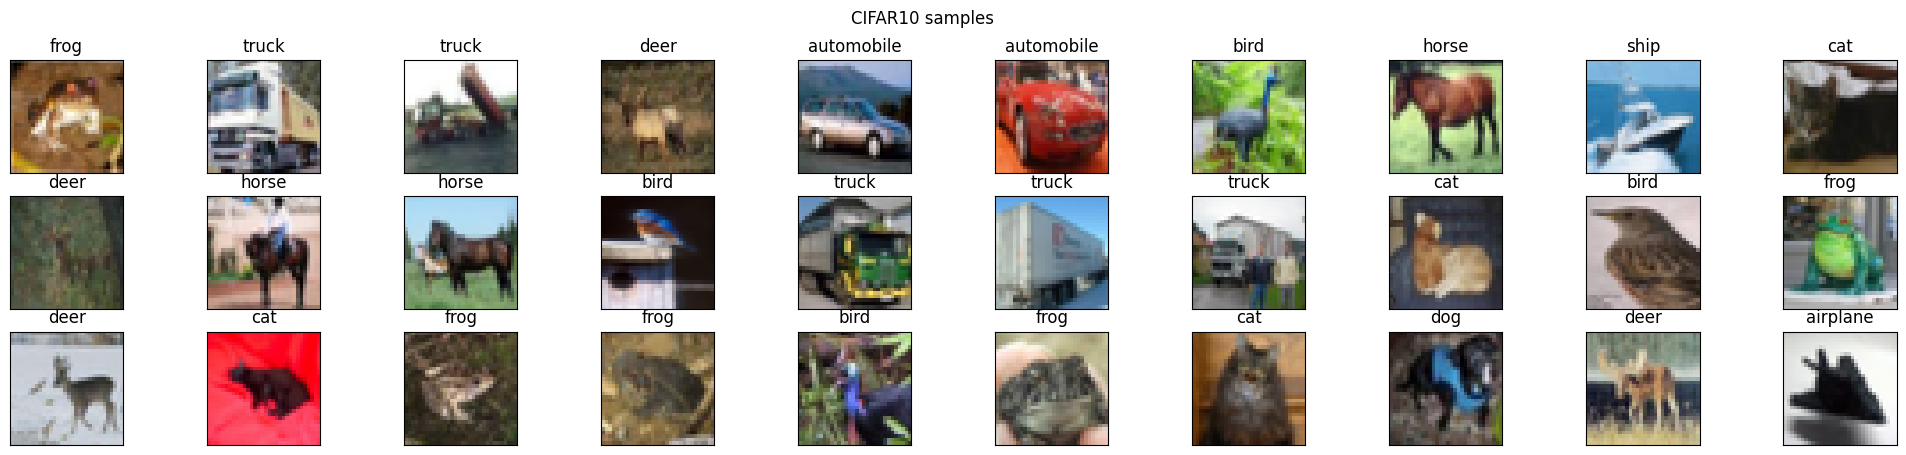

In [19]:
# get cifar10 dataset
transform = transforms.Compose([transforms.ToTensor()])
train_dataset = datasets.CIFAR10('../data', train=True, download=False, transform=transform)
test_dataset = datasets.CIFAR10('../data', train=False, download=False, transform=transform)

# samples from cifar10 dataset
vis = Visualizer(3, 10, figsize=(25, 5), title='CIFAR10 samples')
for i in range(30):
    image = train_dataset[i][0].permute(1, 2, 0).numpy()[:, :, ::-1]
    vis.add_image_subplot(i // 10, i % 10, image, title_str=train_dataset.classes[train_dataset[i][1]])

While we could "train" a linear classifier by solving a linear system, we will use gradient descent to get familiar with training. One epoch is a full pass over the training set. Read the training code below and answer:

* What is the purpose of `optimizer.zero_grad()`, and what would happen without it?
- answer: It zeros the .grad attribute of all model parameters before computing the gradients for the current batch. Without it, he gradients from previous batches would be accumulated, causing optimizer.step() to update the weights using sum of all past gradients, which leads to problematic training performance.
* What is `criterion`, and which function from Lecture 6 does it combine with the softmax?

- It is the loss function.  Cross-entropy.


* How many parameters does the linear model have?

- 30，730

* What accuracy do you expect from a randomly initialised model, and what loss?

- Accuracy: 10%, L=ln(10)|

In [20]:
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=128, shuffle=False)

def evaluate(model, test_loader):
    model.eval()
    model_device = next(model.parameters()).device
    correct = 0
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(model_device), target.to(model_device)
            correct += (model(data).argmax(dim=1) == target).sum().item()
    return 100. * correct / len(test_loader.dataset)

def train(model, train_loader, test_loader, lr=0.001, num_epochs=5):
    # trains on the GPU if there is one; the trained model is returned on the CPU
    model = model.to(device)
    criterion = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(num_epochs):
        model.train()
        for data, target in train_loader:
            data, target = data.to(device), target.to(device)
            optimizer.zero_grad()
            loss = criterion(model(data), target)
            loss.backward()
            optimizer.step()
        print(f'Epoch {epoch + 1}/{num_epochs}, test accuracy: {evaluate(model, test_loader):.2f}%')
    return model.cpu()

class LinearModel(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = torch.nn.Linear(3 * 32 * 32, 10)

    def forward(self, x):
        return self.fc(x.view(-1, 3 * 32 * 32))

linear_model = train(LinearModel(), train_loader, test_loader)

Epoch 1/5, test accuracy: 37.43%
Epoch 2/5, test accuracy: 37.35%
Epoch 3/5, test accuracy: 36.26%
Epoch 4/5, test accuracy: 34.01%
Epoch 5/5, test accuracy: 37.44%


Visualise the weights of the linear layer: each class has $3 \cdot 32 \cdot 32$ weights, which you can show as an image (a *template* for that class).

Then train a second linear model on training data that is randomly flipped left-right (`transforms.RandomHorizontalFlip()`; keep the test set unchanged) and visualise its weights next to the first ones. The change is subtle: also show the difference between each template and its mirror image (`w - w[:, ::-1]`) for both models. What changed, and why? What does this tell you about the relation between data augmentation and invariance?


- With horizontal flip augmentation, the weight templates tend to become more horizontally symmetric. Because model is trained on both original and horizontally flipped images with the same labels, encouraging it to learn features that are less sensitive to left-right orientation. This shows that data augmentation encourages invariance to the transformations used during training.

Epoch 1/5, test accuracy: 34.31%
Epoch 2/5, test accuracy: 31.08%
Epoch 3/5, test accuracy: 36.72%
Epoch 4/5, test accuracy: 37.11%
Epoch 5/5, test accuracy: 37.99%


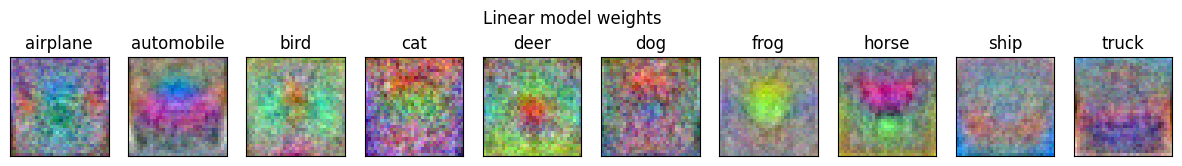

In [24]:
def show_linear_weights(model, title):
    vis = Visualizer(1, 10, figsize=(15, 2), title=title)

    for i in range(10):
        weights = model.fc.weight[i].detach().cpu().reshape(3, 32, 32).permute(1, 2, 0).numpy()[:, :, ::-1]

        vis.add_image_subplot(
            0, i, weights,
            title_str=train_dataset.classes[i],
            normalize=True
        )

show_linear_weights(linear_model, 'Linear model weights')

# TODO: train a linear model with horizontal flip augmentation and show its weights

transform_flip = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor()
])

train_dataset_flip = datasets.CIFAR10(
    '../data',
    train=True,
    download=False,
    transform=transform_flip
)

train_loader_flip = torch.utils.data.DataLoader(
    train_dataset_flip,
    batch_size=128,
    shuffle=True
)


linear_model_flip = train(LinearModel(), train_loader_flip, test_loader)

Now define and train a small CNN with
* Convolution: kernel 5x5, 3 input channels, **12** filters, **no** padding
* ReLU
* Max-pooling: 2x2, stride 2
* Fully connected layer to 10 classes

Answer:
* What is the input size of the fully connected layer? Derive it before you run the code.
- The input size of the fully connected layer is 2352.

* How many parameters does the CNN have, compared to the linear model? Why can it nevertheless be more accurate?

The CNN has 24442 parameters. Because convolution uses local connectivity and weight sharing to detect spatial features efficiently. ReLU also introduces non-linearity, allowing the CNN to learn more complex patterns than a linear classifier.

* Why are the convolution and the FC layer defined in `__init__()`, while ReLU and max-pooling are only used in `forward()`?

- Convolutional and fully connected layers contain learnable weights and biases, so they are defined in __init__() to register their parameters. ReLU and max pooling have no learnable parameters, so they can be applied directly as functions in forward().

In [27]:
class MiniCNN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: define the layers with parameters
        self.conv = torch.nn.Conv2d(3, 12, kernel_size=5)
        self.fc = torch.nn.Linear(12 * 14 * 14, 10)

    def forward(self, x):
        # TODO: define the forward pass
        x = self.conv(x)
        x = torch.relu(x)
        x = torch.nn.functional.max_pool2d(x, 2, stride=2)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

cnn = train(MiniCNN(), train_loader, test_loader)  # about 57% after 5 epochs
print('parameters:', sum(p.numel() for p in cnn.parameters()))

Epoch 1/5, test accuracy: 47.68%
Epoch 2/5, test accuracy: 51.42%
Epoch 3/5, test accuracy: 53.76%
Epoch 4/5, test accuracy: 54.27%
Epoch 5/5, test accuracy: 56.62%
parameters: 24442


After 5 epochs the linear model reaches about 37% and the CNN about 57%. Visualise the 12 learned first-layer filters (each is $5 \times 5 \times 3$) as small colour images and compare them to the first-layer filters shown in Lecture 7. Then add a second block (convolution 3x3 with **24** filters and padding 1, ReLU, max-pooling 2x2 with stride 2) and confirm that this improves the accuracy (to about 60%).

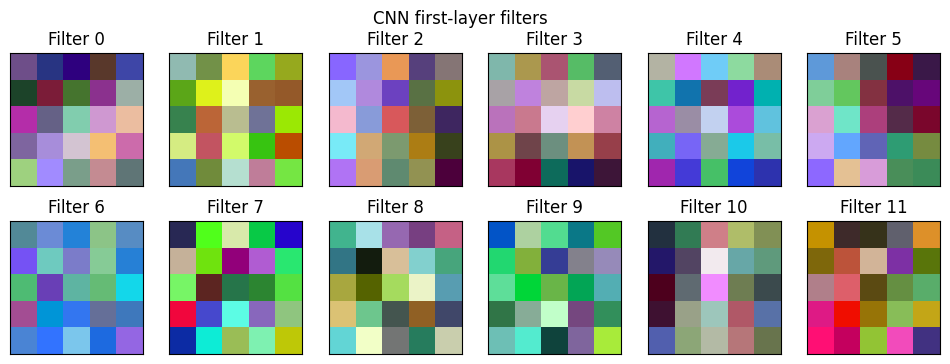

In [29]:
# Visualise the first-layer filters of cnn
vis = Visualizer(2, 6, figsize=(12, 4), title='CNN first-layer filters')

for i in range(12):
    w = cnn.conv.weight[i].detach().cpu()
    w = w.permute(1, 2, 0).numpy()[:, :, ::-1]

    vis.add_image_subplot(
        i // 6, i % 6,
        w,
        title_str=f'Filter {i}',
        normalize=True
    )

In [28]:


class MiniCNN2(torch.nn.Module):
    def __init__(self):
        super().__init__()
        # First convolutional block
        self.conv1 = torch.nn.Conv2d(3, 12, kernel_size=5)

        # Second convolutional block
        self.conv2 = torch.nn.Conv2d(12, 24, kernel_size=3, padding=1)

        # Fully connected layer
        self.fc = torch.nn.Linear(24 * 7 * 7, 10)

    def forward(self, x):
        # First block
        x = self.conv1(x)
        x = torch.relu(x)
        x = torch.nn.functional.max_pool2d(x, 2, stride=2)

        # Second block
        x = self.conv2(x)
        x = torch.relu(x)
        x = torch.nn.functional.max_pool2d(x, 2, stride=2)

        # Flatten and classify
        x = x.view(x.size(0), -1)
        x = self.fc(x)

        return x

cnn2 = train(MiniCNN2(), train_loader, test_loader, lr=0.002)

Epoch 1/5, test accuracy: 50.43%
Epoch 2/5, test accuracy: 54.41%
Epoch 3/5, test accuracy: 59.66%
Epoch 4/5, test accuracy: 61.09%
Epoch 5/5, test accuracy: 63.27%


### Optional Task - Be a hero
Find a combination that beats `MiniCNN2` by at least 5 percentage points (i.e. at least 65%): change the architecture, train longer, tune hyper-parameters, or add data augmentation (we have seen flips above). Do not change the test set! (State-of-the-art models reach around 99%.)

Hint: use a GPU runtime. `train` and `evaluate` above already move the model and every batch to the GPU if there is one.

## Problem 2.2 - Occlusion and Attention in a Vision Transformer

In the lecture we occluded image regions of a CNN to see which parts matter. A Vision Transformer (ViT) already cuts the image into 16x16 patches (tokens), so we can occlude *tokens* directly. We load a ViT-B/16 trained on ImageNet. It runs on the GPU if there is one (`device`).

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:06<00:00, 55.4MB/s]


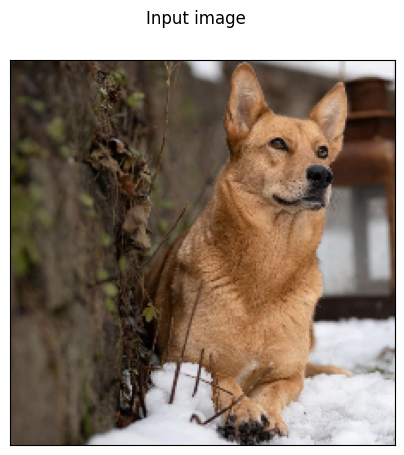

In [30]:
vit = torchvision.models.vit_b_16(weights=torchvision.models.ViT_B_16_Weights.IMAGENET1K_V1).eval().to(device)
class_names = torchvision.models.ViT_B_16_Weights.IMAGENET1K_V1.meta['categories']

def load_imagenet_image(path):
    image = cv2.imread(path)
    image = image[:, :image.shape[0]]  # square crop
    image = cv2.resize(image, (224, 224))
    display = image.copy()
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) / 255.0
    image = (image - np.array([0.485, 0.456, 0.406])) / np.array([0.229, 0.224, 0.225])
    image = torch.from_numpy(image.transpose(2, 0, 1)[None]).float()
    return image, display

image, display = load_imagenet_image('image_dog.jpg')
vis = Visualizer(num_rows=1, num_cols=1, figsize=(5, 5), axis_off=True, title='Input image')
vis.add_image_subplot(0, 0, display)

Below is a function `predict` that runs the ViT step by step. Explain:
* the role of `class_token`,
- The class token is a learnable token added to the beginning of the patch token sequence. Through self-attention, it gathers information from the image patches. It is the representation of the image.



* `encoder.pos_embedding` and why it is needed (Sheet 3, Q2.2),

encoder.pos_embedding adds positional information to the patch embeddings. Self-attention alone does not encode the spatial positions of tokens. Without positional embeddings, the ViT cannot distinguish different spatial arrangements of the same image patches.

* the reason for `x[:, 0]`.
x[:, 0] is the CLS token, which aggregates information from the image patches through self-attention.


In [31]:
def embed(vit, image):
    x = vit._process_input(image.to(device))  # B x 196 x 768 patch tokens
    class_token = vit.class_token.expand(x.shape[0], -1, -1)
    x = torch.cat([class_token, x], dim=1)
    return x + vit.encoder.pos_embedding  # B x 197 x 768

def classify(vit, x):
    x = vit.encoder.ln(vit.encoder.layers(vit.encoder.dropout(x)))
    return vit.heads(x[:, 0])

def predict(vit, image):
    with torch.no_grad():
        return classify(vit, embed(vit, image))[0].cpu().numpy()

output = predict(vit, image)
print(f'Predicted class: {class_names[output.argmax()]}')

Predicted class: dingo


Implement two ways of occluding patch token $i$ (careful: token 0 is the class token):
1. **zero**: set the token to zero *after* adding the positional embedding,
2. **remove**: delete the token from the sequence. A CNN cannot do this (it needs a full grid), but a transformer can process a shorter sequence.

For each patch, measure the drop of the logit of the predicted class and show both heatmaps ($14 \times 14$). How similar are they (e.g. their correlation)? Which one would you trust more in general, and why?

In [ ]:
def predict_occluded(vit, image, token, mode):
    with torch.no_grad():
        x = embed(vit, image)
        # TODO: occlude patch token `token` ('zero' or 'remove')
        return classify(vit, x)[0].cpu().numpy()

top_class = output.argmax()
heatmaps = {}
for mode in ['zero', 'remove']:
    heatmap = np.zeros((14, 14))
    # TODO: fill the heatmap
    heatmaps[mode] = heatmap

vis = Visualizer(num_rows=1, num_cols=3, figsize=(15, 5), axis_off=True, title='Occlusion')
vis.add_image_subplot(0, 0, display)
vis.add_image_subplot(0, 1, heatmaps['zero'], title_str='zero token')
vis.add_image_subplot(0, 2, heatmaps['remove'], title_str='remove token')

Lecture 9 showed attention maps as a different kind of explanation. Compute the attention of the class token to all patch tokens in the **last** encoder layer, averaged over the heads, and show it next to your occlusion map.

Hint: the encoder blocks call `self_attention` with `need_weights=False`. Run the blocks yourself and, for the last block, call `block.self_attention(y, y, y, need_weights=True, average_attn_weights=True)` on the layer-normalised input `y = block.ln_1(x)`. The ViT runs on the GPU if there is one, so call `.cpu()` before `.numpy()`.

Do the two maps agree? Which one would you use to *explain the decision*, and why?

In [ ]:
def last_layer_cls_attention(vit, image):
    # TODO: return a 14 x 14 map of the class token's attention to the patch tokens in the last layer
    return np.zeros((14, 14))

attention = last_layer_cls_attention(vit, image)
vis = Visualizer(num_rows=1, num_cols=3, figsize=(15, 5), axis_off=True, title='Occlusion vs. attention')
vis.add_image_subplot(0, 0, display)
vis.add_image_subplot(0, 1, heatmaps['remove'], title_str='occlusion (remove)')
vis.add_image_subplot(0, 2, attention, title_str='CLS attention, last layer')

### Optional Task - Visualise Everything
Upload your own images and show predictions and heatmaps. Are there clear failure modes? What happens if you visualise a class that is not in the image?

## Problem 2.3 - Adversarial Examples

Adversarial examples look normal to humans but make a network predict a wrong class (as its top-1 prediction). We construct one by gradient ascent on the *pixels*: start from the dog image, and take small steps that increase the logit of a target class. No regularisers are needed since we stay close to the original image.

* Write `de_normalise_image` (invert the preprocessing, return a BGR image for the `Visualizer`) and test it on the original image.
* Use a ResNet-50 and the target class 954 (`banana`).
* Stop as soon as the target class has the highest logit and report the number of iterations.
* Show the adversarial image, the difference to the original (scaled up), and the largest change of any pixel value in units of the 8-bit range (multiply the de-normalised difference by 255).

In [ ]:
resnet = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.DEFAULT).eval()
image, display = load_imagenet_image('image_dog.jpg')

def de_normalise_image(x):
    # TODO: invert the normalisation and return an H x W x 3 BGR image in [0, 1]
    return x

print(f'Predicted class: {class_names[resnet(image).argmax()]}')

target_class = 954  # banana
adversarial = torch.nn.Parameter(image.clone())
optimizer = torch.optim.Adam([adversarial], lr=0.01)
# TODO: optimise until the target class wins

# TODO: visualise the adversarial example, the difference, and print the largest pixel change

**Do adversarial examples transfer?** Feed your adversarial example to the ViT from Problem 2.2 (`predict(vit, x)` takes care of moving it to the GPU). Does it also predict `banana`? Then continue optimising the ResNet example for 50 more iterations *after* the target class wins and test the transfer again. What do you conclude about how these examples exploit a model, and why does transfer matter for the security of deployed systems?

In [ ]:
# TODO: test the adversarial example on the ViT, then optimise further and test again

## Optional Tasks
* Save the adversarial example as a JPEG and load it again. Does it still work? Why? How could you make it more robust?
* Universal perturbations: find a single noise pattern $\epsilon$ that, added to *any* CIFAR10 image, makes your `MiniCNN2` predict a target class. Learn $\epsilon$ on the training set (the model stays fixed), keeping every pixel change within $\pm 16/255$ (the images are in $[0, 1]$), with target class `cat`. Report the fraction of test images classified as `cat` and show examples. How do they compare to the adversarial examples above?